# Stage 6 — Within-class clustering

Chỉ chọn potentially_dangerous trong train bằng nhãn thật. Nhãn không vào features. Week 6: scaling/K-means/inertia/silhouette/profiling/PCA. Week 7: DBSCAN là phần tùy chọn, chưa chạy.

Code dùng lại `src/dtdlink_ml/cluster_urls.py`; không viết lại thuật toán trong notebook.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from dtdlink_ml import cluster_urls as clustering
from dtdlink_ml.feature_extraction import file_sha256
# Đổi thành True để chạy lại toàn quy trình; False đọc kết quả đã lưu.
RUN_CLUSTERING = False
if RUN_CLUSTERING:
    clustering.run()
REPORT = ROOT / "reports/clustering"
summary = json.loads((REPORT / "clustering_summary.json").read_text())
assert file_sha256(clustering.FEATURE_INPUT) == summary["feature_sha256"]
assert file_sha256(clustering.SPLIT_MANIFEST) == summary["manifest_sha256"]
print("Population:", summary["selected_rows"], "URLs;", len(summary["feature_names"]), "features")
print("Removed constants:", summary["removed_constant_features"])
print("Selected k:", summary["selected_k"])
print("Labels used as features:", summary["labels_used_as_features"])

Population: 127256 URLs; 34 features
Removed constants: ['brand_in_userinfo', 'has_confusable_unicode']
Selected k: 7
Labels used as features: False


## So sánh k và độ ổn định

Silhouette tính trên cùng mẫu 2.000 dòng. Chọn điểm cao nhất, hòa chọn k nhỏ hơn. Xem thêm nhóm nhỏ và ARI giữa các seed; ARI không phải accuracy. Mẫu có thể bỏ sót nhóm hiếm.

In [2]:
comparison = pd.read_csv(REPORT / "k_comparison.csv")
print(comparison.to_string(index=False))
print("Cluster sizes:", summary["cluster_sizes"])
print("ARI:", summary["stability_ari"])
print("Silhouette sample per cluster:", summary["silhouette_sample_cluster_sizes"])

 k      inertia  silhouette  min_cluster_size  max_cluster_size  iterations  sample_size  sampled_cluster_count
 2 3.913159e+06    0.161959             41802             85454           5         2000                      2
 3 3.581522e+06    0.198826              2951             82537           4         2000                      3
 4 3.308138e+06    0.244642              2951             76486          18         2000                      4
 5 3.054857e+06    0.256137              1986             53774          17         2000                      5
 6 2.860147e+06    0.283951              1069             51140          13         2000                      6
 7 2.651905e+06    0.292263                53             47106          10         2000                      7
 8 2.411112e+06    0.285758                53             51454          44         2000                      8
Cluster sizes: {'0': 40662, '1': 26369, '2': 53, '3': 5730, '4': 4386, '5': 47106, '6': 2950}
ARI: {'43'

## Profiles và URL đại diện

Trung bình/tỷ lệ ở thang đo gốc; difference_in_std so với toàn class đã chọn. Các URL dưới đây là chuỗi JSON đã escape, không truy cập và không làm liên kết.

In [3]:
profiles = pd.read_csv(REPORT / "cluster_profiles.csv")
examples = pd.read_csv(REPORT / "representative_urls.csv", keep_default_na=False)
for cluster, group in profiles.groupby("cluster"):
    print("\nCLUSTER", cluster, "size", int(group.iloc[0]["size"]))
    print(clustering.describe_cluster(group))
    top = group.loc[group.difference_in_std.abs().nlargest(5).index]
    print(top[["feature", "cluster_mean", "overall_mean", "difference_in_std"]].to_string(index=False))
    for url in examples.loc[examples.cluster.eq(cluster), "url"]:
        print(json.dumps(url, ensure_ascii=True))


CLUSTER 0 size 40662
Nhóm URL ngắn, không ghi scheme; parse_issue_count thường phản ánh missing_scheme có thể phục hồi, không đồng nghĩa parser thất bại. Có thể bị chi phối bởi định dạng nguồn.
                feature  cluster_mean  overall_mean  difference_in_std
             has_scheme      0.000000      0.670019          -1.424950
      parse_issue_count      1.000000      0.330515           1.419354
special_character_count      4.411465     10.526773          -0.856417
             url_length     31.215410     63.312331          -0.701936
  query_parameter_count      0.039693      1.080876          -0.519463
"www.sulekhab2b.com/vastrakala/"
"s1.zetaboards.com/ShadowsideRPG/"
"home.earthlink.net/~sturges47/"

CLUSTER 1 size 26369
Nhóm URL dài với nhiều tham số query, có thể gồm cấu trúc CMS lặp lại. Đây là mẫu hình văn bản, không đủ để xác nhận phishing.
                feature  cluster_mean  overall_mean  difference_in_std
  query_parameter_count      4.537866      1.080876       

## Nhãn nguồn: kiểm tra sau phân cụm

Bảng này chỉ kiểm tra thành phần nguồn. Type không được dùng để tạo clusters hoặc chọn k. Scheme và domain lặp lại có thể chi phối nhóm.

In [4]:
composition = pd.read_csv(REPORT / "source_type_composition.csv")
print(composition.to_string(index=False))
print("Domain concentration:", json.dumps(summary["cluster_domain_concentration"], indent=2))
assignments = pd.read_csv(REPORT / "cluster_assignments.csv")
assert assignments.url_id.is_unique
assert len(assignments) == summary["selected_rows"]
assert assignments.cluster.value_counts().sort_index().tolist() == list(summary["cluster_sizes"].values())
assert profiles.groupby("cluster")["size"].first().sum() == len(assignments)
assert composition["count"].sum() == len(assignments)
assert not summary["test_used_for_modelling_or_metrics"]
print("Saved result reconciliation: PASS")

 cluster source_type  count  proportion
       0     malware    616    0.015149
       0    phishing  40046    0.984851
       1  defacement  24832    0.941712
       1     malware    560    0.021237
       1    phishing    977    0.037051
       2    phishing     53    1.000000
       3  defacement    311    0.054276
       3     malware    162    0.028272
       3    phishing   5257    0.917452
       4     malware   4236    0.965800
       4    phishing    150    0.034200
       5  defacement  30589    0.649365
       5     malware   6692    0.142063
       5    phishing   9825    0.208572
       6     malware   2922    0.990508
       6    phishing     28    0.009492
Domain concentration: {
  "0": {
    "unique_groups": 21494,
    "largest_group": "domain:ietf.org",
    "largest_group_rows": 3212,
    "largest_group_share": 0.07899267129014804
  },
  "1": {
    "unique_groups": 1063,
    "largest_group": "domain:live.com",
    "largest_group_rows": 313,
    "largest_group_share": 0

## Biểu đồ

PCA chỉ hỗ trợ quan sát; tỷ lệ phương sai giải thích phải được đọc cùng hình. Clusters không là mức độ nguy hiểm.

PCA variance: [0.14901498316825004, 0.0937665175986427]


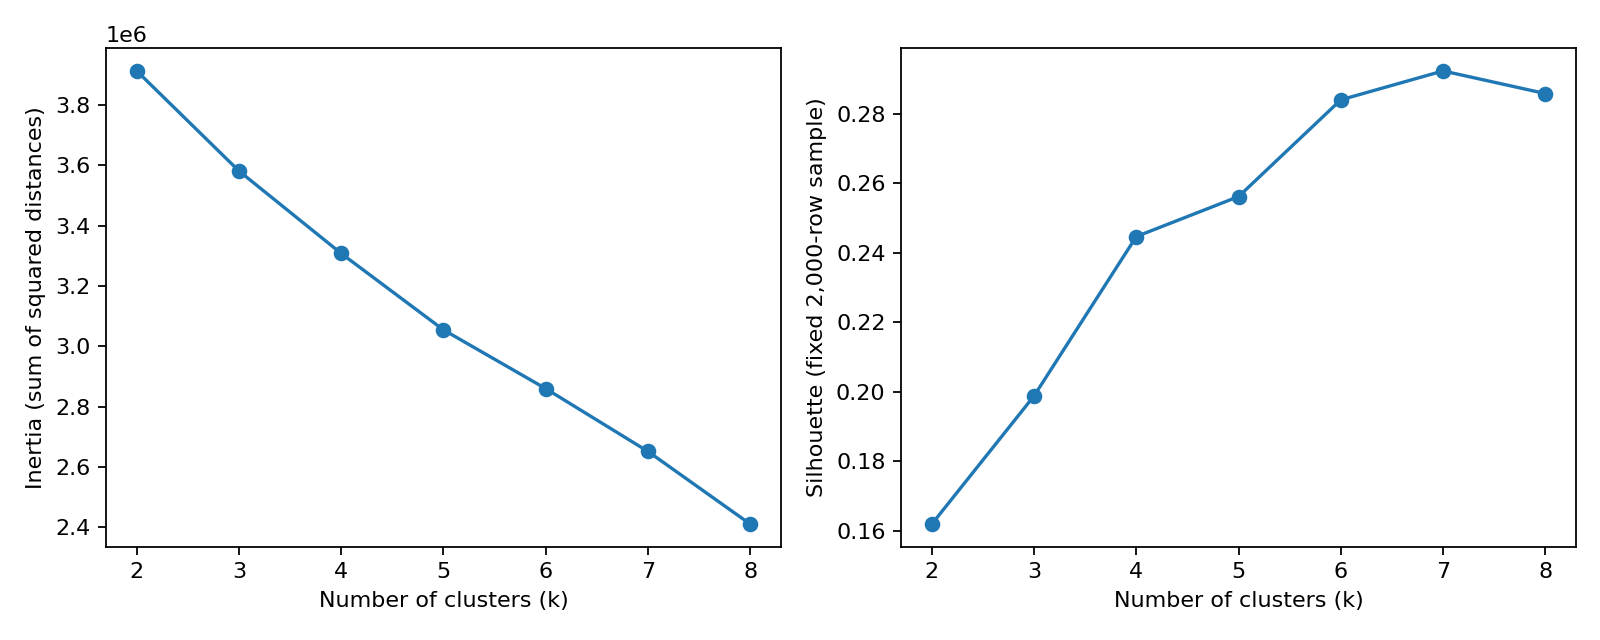

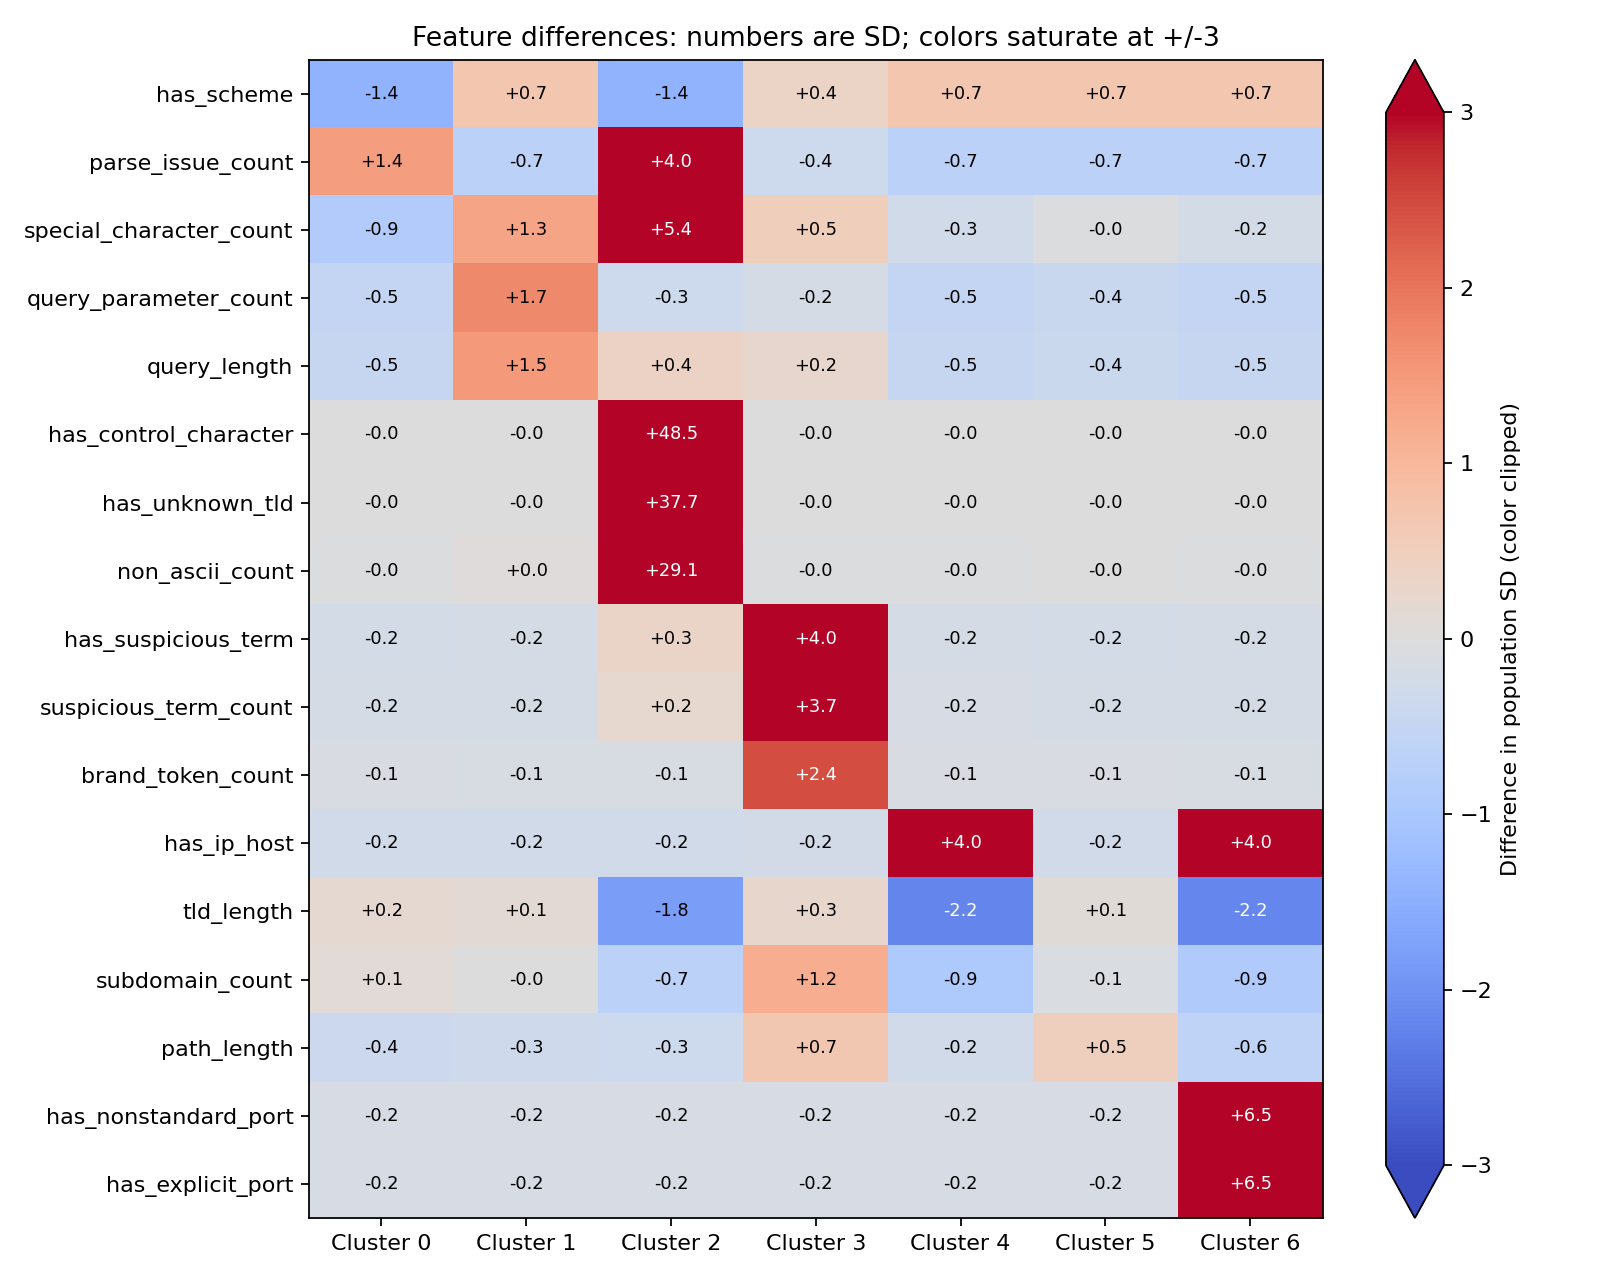

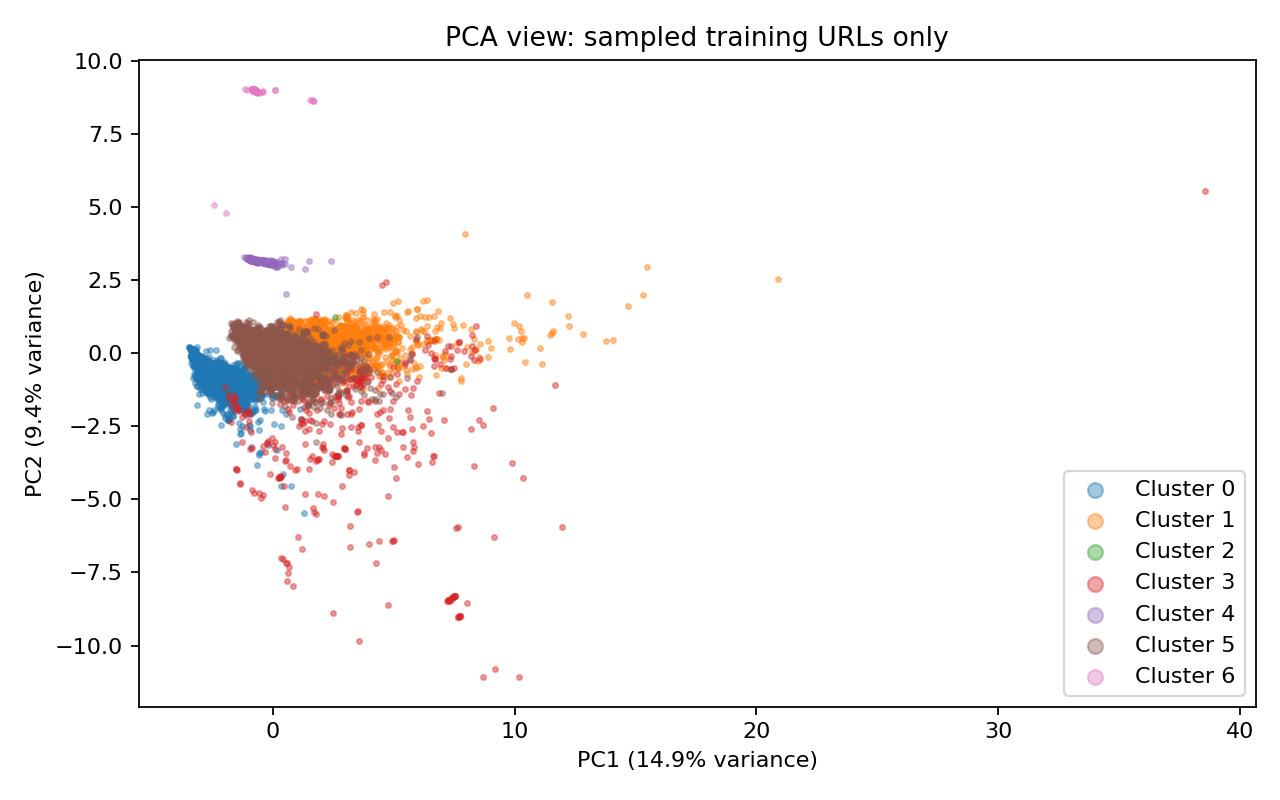

In [5]:
print("PCA variance:", summary["pca_explained_variance_ratio"])
for name in ["clustering_k_selection.png", "clustering_profiles.png", "clustering_pca.png"]:
    display(Image(filename=str(ROOT / "reports/figures" / name)))

## Kết luận và phần có thể điều chỉnh

Xem báo cáo `reports/clustering/stage-6-clustering-report.md`. StandardScaler nhạy với tín hiệu hiếm/outliers, các features tương quan có thể bị tính trọng số nhiều lần. ARI cho thấy thay đổi theo seed; kết quả không chứng minh có đúng một cấu trúc nhóm.

Settings trong module: `K_VALUES`, `RANDOM_SEED`, `N_INIT`, `SILHOUETTE_SAMPLE_SIZE`, `PCA_SAMPLE_SIZE`, `REPRESENTATIVES_PER_CLUSTER`. Thay setting phải chạy lại toàn bộ và xem lại diễn giải. Không đổi class/split tùy tiện. Test set giữ cho Stage 7; Random Forest và threshold 0.5 giữ quyết định Stage 5.